# 02 · Zero-shot classification and prompt engineering

**Zero-shot** means: classify images into classes the model was never explicitly trained on, using **no labeled examples at all**. All you provide is the *names* of the classes.

The trick: write each class name into a sentence ("a photo of a beagle"), embed the sentences with the text encoder, and treat those text vectors as the **weights of a linear classifier**. An image is assigned to the class whose text vector it is most similar to.

```
W      = text_encoder(prompts)          # (n_classes, d), one unit vector per class
logits = image_embeddings @ W.T          # (n_images, n_classes), cosine similarities
pred   = logits.argmax(axis=1)
```

Because the "classifier" is just text, **the wording of the prompts is a hyperparameter**. Most of this notebook is about that: prompt engineering for vision.

Requires the embedding cache from [01_embeddings.ipynb](01_embeddings.ipynb).

In [1]:
%load_ext autoreload
%autoreload 2
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

import clip_utils as cu

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

models = {k: cu.load_model(k) for k in cu.MODELS}
DATASETS = ["pets", "pathmnist"]
test = {(key, name): cu.load_embeddings(key, name, "test") for key in models for name in DATASETS}
for (key, name), (E, y, classes) in test.items():
    print(f"{key:7s} {name:10s} test embeddings {E.shape}, {len(classes)} classes")

.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


clip    pets       test embeddings (1110, 512), 37 classes
clip    pathmnist  test embeddings (900, 512), 9 classes
siglip  pets       test embeddings (1110, 768), 37 classes
siglip  pathmnist  test embeddings (900, 768), 9 classes


## 1. Zero-shot in five lines

The simplest version: CLIP, Pets, and the generic prompt `"a photo of a {class}."`

In [2]:
m, p = models["clip"]
E, y, classes = test["clip", "pets"]

W = cu.zeroshot_weights(m, p, [[f"a photo of a {c}."] for c in classes])  # (37, 512)
pred = (E @ W.T).argmax(1)
print(f"CLIP zero-shot accuracy on Pets: {(pred == y).mean():.1%}  (chance = {1 / len(classes):.1%})")

CLIP zero-shot accuracy on Pets: 86.4%  (chance = 2.7%)


No training, no labeled pet photos, and the model picks the right breed out of 37 most of the time.

## 2. From similarities to probabilities: softmax (CLIP) vs. sigmoid (SigLIP)

The two models were trained with different losses, so their scores mean different things:

* **CLIP** was trained with a softmax over the batch. Its class probabilities are `softmax(scale · cos)`. They sum to 1: the classes compete.
* **SigLIP** was trained with an independent sigmoid per image–text pair. Each class gets its own `sigmoid(scale · cos + bias)`, a yes/no "does this caption match?" score. They do **not** sum to 1. An image can match several labels, or none.

For single-label classification the **argmax is the same either way**; only the interpretation of the score changes.

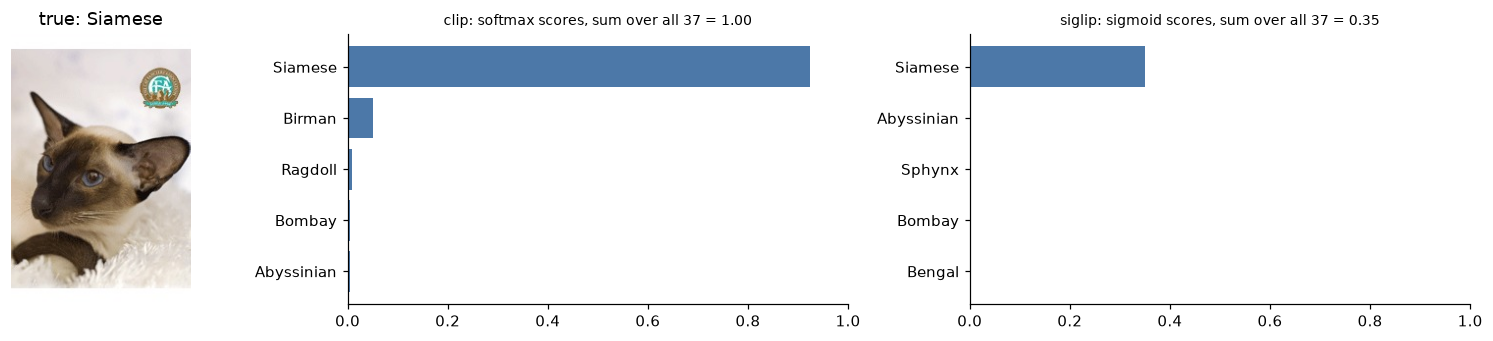

In [3]:
s = cu.load_imageset("pets", "test")
i = int(np.flatnonzero(s.labels == s.classnames.index("Siamese"))[0])

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), gridspec_kw={"width_ratios": [1, 2, 2]})
axes[0].imshow(s.image(i)); axes[0].axis("off"); axes[0].set_title(f"true: {s.classnames[s.labels[i]]}")
for ax, key in zip(axes[1:], models):
    m, p = models[key]
    E, y, classes = test[key, "pets"]
    W = cu.zeroshot_weights(m, p, [[f"a photo of a {c}, a type of pet."] for c in classes])
    scale, bias = cu.logit_params(m)
    logits = scale * (E[i] @ W.T) + bias
    probs = np.exp(cu.log_softmax(logits)) if key == "clip" else 1 / (1 + np.exp(-logits))
    top = np.argsort(-probs)[:5]
    ax.barh([classes[t] for t in top][::-1], probs[top][::-1], color="#4c78a8")
    ax.set_xlim(0, 1)
    ax.set_title(f"{key}: {'softmax' if key == 'clip' else 'sigmoid'} scores, sum over all 37 = {probs.sum():.2f}", fontsize=9)
fig.tight_layout()

## 3. Prompt engineering

Each **prompt strategy** is a function from a class name to a list of prompts. When it returns several prompts, their embeddings are averaged into one class vector (**prompt ensembling**, from the original CLIP paper). The ideas tested, from least to most effort:

| Strategy | Idea |
|---|---|
| `name only` | Just the class name. Text encoders saw captions, not bare words, so this is usually the weakest. |
| `a photo of a {}` | The generic CLIP default. |
| `+ domain context` | Say what kind of image it is: "a type of pet", "a histopathology image". This disambiguates words with several meanings ("Boxer", "Sphynx", "debris"). |
| `+ species` / `+ descriptions` | Inject knowledge: whether the breed is a cat or a dog; or what each tissue *looks like* ("large empty white fat cells"). |
| `ensemble` | Many phrasings (close-up, blurry, low-resolution …) averaged together, so no single wording dominates. |

In [4]:
# ---- Oxford-IIIT Pets
PET_TEMPLATES = [
    "a photo of a {}, a type of pet.",
    "a close-up photo of a {}, a type of pet.",
    "a blurry photo of a {}, a type of pet.",
    "a photo of my {}, a type of pet.",
    "a photo of the cute {}, a type of pet.",
    "a low resolution photo of a {}, a type of pet.",
    "a cropped photo of a {}, a type of pet.",
    "a bright photo of a {}, a type of pet.",
]

def species(c):
    return "cat" if c in cu.PET_CATS else "dog"

PET_STRATEGIES = {
    "name only": lambda c: [c],
    "a photo of a {}": lambda c: [f"a photo of a {c}."],
    "+ domain context": lambda c: [f"a photo of a {c}, a type of pet."],
    "+ species": lambda c: [f"a photo of a {c}, a breed of {species(c)}."],
    "ensemble": lambda c: [t.format(c) for t in PET_TEMPLATES],
    "ensemble + species": lambda c: [t.replace("a type of pet", f"a breed of {species(c)}").format(c) for t in PET_TEMPLATES],
}

# ---- PathMNIST (NCT-CRC-HE-100K colorectal histology)
PATH_DESCRIPTIONS = {
    "adipose": ["adipose tissue", "fat cells with large empty white vacuoles"],
    "background": ["empty background with no tissue", "a blank white glass slide"],
    "debris": ["necrotic debris", "cellular debris and necrosis"],
    "lymphocytes": ["lymphocytes", "dense sheets of small round dark purple immune cells"],
    "mucus": ["mucus", "pale bluish acellular mucin"],
    "smooth muscle": ["smooth muscle", "bundles of pink elongated smooth muscle fibers"],
    "normal colon mucosa": ["normal colon mucosa", "regular colonic crypts lined by goblet cells"],
    "cancer-associated stroma": ["cancer-associated stroma", "loose pink fibrous connective tissue"],
    "colorectal adenocarcinoma epithelium": ["colorectal adenocarcinoma epithelium",
                                             "crowded irregular malignant glands of colon cancer"],
}
PATH_TEMPLATES = [
    "a histopathology image of {}.",
    "an H&E stained microscopy image of {}.",
    "a microscopic image of {} in colon tissue.",
    "a pathology slide showing {}.",
]

PATH_STRATEGIES = {
    "name only": lambda c: [c],
    "a photo of a {}": lambda c: [f"a photo of {c}."],
    "+ domain context": lambda c: [f"a histopathology image of {c}."],
    "+ descriptions": lambda c: [f"a histopathology image of {d}." for d in PATH_DESCRIPTIONS[c]],
    "ensemble": lambda c: [t.format(c) for t in PATH_TEMPLATES],
    "ensemble + descriptions": lambda c: [t.format(d) for t in PATH_TEMPLATES for d in PATH_DESCRIPTIONS[c]],
}

STRATEGIES = {"pets": PET_STRATEGIES, "pathmnist": PATH_STRATEGIES}
print("example prompts for 'Sphynx':", PET_STRATEGIES["ensemble + species"]("Sphynx")[:2])
print("example prompts for 'adipose':", PATH_STRATEGIES["ensemble + descriptions"]("adipose")[:3])

example prompts for 'Sphynx': ['a photo of a Sphynx, a breed of cat.', 'a close-up photo of a Sphynx, a breed of cat.']
example prompts for 'adipose': ['a histopathology image of adipose tissue.', 'a histopathology image of fat cells with large empty white vacuoles.', 'an H&E stained microscopy image of adipose tissue.']


In [5]:
rows, weights = [], {}
for name in DATASETS:
    for key, (m, p) in models.items():
        E, y, classes = test[key, name]
        for strat, fn in STRATEGIES[name].items():
            W = cu.zeroshot_weights(m, p, [fn(c) for c in classes])
            weights[key, name, strat] = W
            pred = (E @ W.T).argmax(1)
            rows.append({"dataset": name, "model": key, "strategy": strat, "n_prompts": len(fn(classes[0])),
                         "accuracy": (pred == y).mean()})
zs = pd.DataFrame(rows)
zs.pivot_table(index=["dataset", "strategy"], columns="model", values="accuracy", sort=False).style.format("{:.1%}")

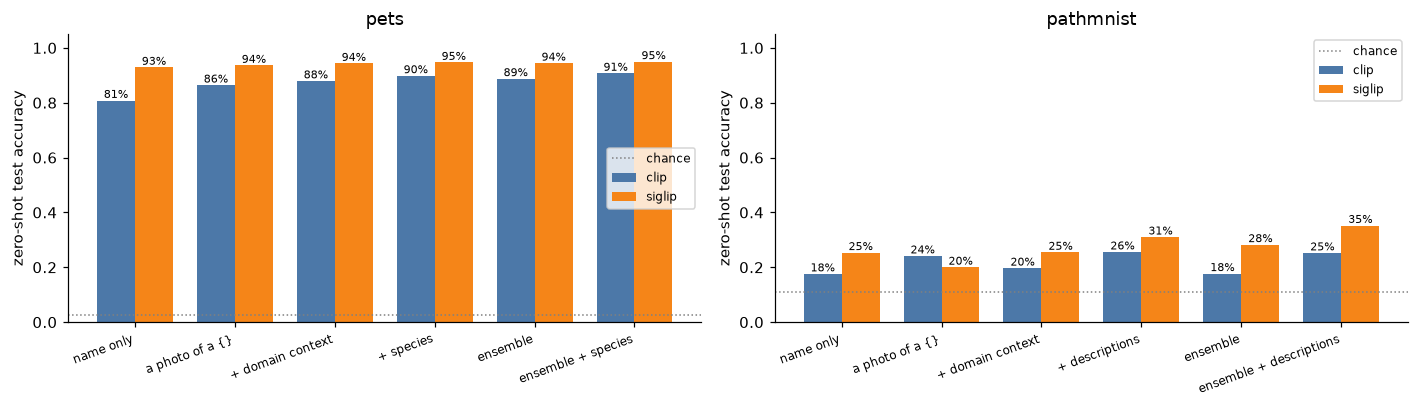

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, name in zip(axes, DATASETS):
    d = zs[zs.dataset == name]
    strats = list(STRATEGIES[name])
    x = np.arange(len(strats))
    for k, (key, color) in enumerate(zip(models, ["#4c78a8", "#f58518"])):
        acc = d[d.model == key].set_index("strategy").loc[strats, "accuracy"].values
        bars = ax.bar(x + (k - 0.5) * 0.38, acc, 0.38, label=key, color=color)
        ax.bar_label(bars, [f"{a:.0%}" for a in acc], fontsize=7)
    ax.axhline(1 / len(test["clip", name][2]), color="gray", ls=":", lw=1, label="chance")
    ax.set_xticks(x, strats, rotation=20, ha="right", fontsize=8)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("zero-shot test accuracy")
    ax.set_title(name)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(cu.FIG_DIR / "zero_shot_prompts.png", bbox_inches="tight")

**How to read this.**

* **Pets, CLIP:** prompt wording is worth 10 points, from 80.8% (bare name) to 90.7% (ensemble + species). Each lever helps: a sentence template (+5.6), domain context (+1.5), and telling the model whether the breed is a cat or a dog (+1.9).
* **Pets, SigLIP:** already 92.9% with bare names. SigLIP's text encoder is much less sensitive to wording, so prompt engineering adds only ~2 points.
* **PathMNIST:** the best strategy reaches 25.6% (CLIP) and 35.2% (SigLIP), against 11% chance. Visual descriptions help most ("fat cells with large empty white vacuoles"). But wording effects are erratic: "a photo of …" *helps* CLIP and *hurts* SigLIP, and template ensembling helps SigLIP but hurts CLIP. That is what prompt tuning looks like when the model has no real grip on the domain. Every strategy stays far below what the image features can support (notebook 03 shows how far).

A caution about method: this table picks the best prompt **by looking at test accuracy**. That is fine for learning, but it is a mild form of overfitting to the test set. In a real project you'd choose prompts on a held-out validation split, or commit to a strategy before looking.

## 4. Where does zero-shot go wrong?

Confusion matrices for the best strategy per dataset and model.

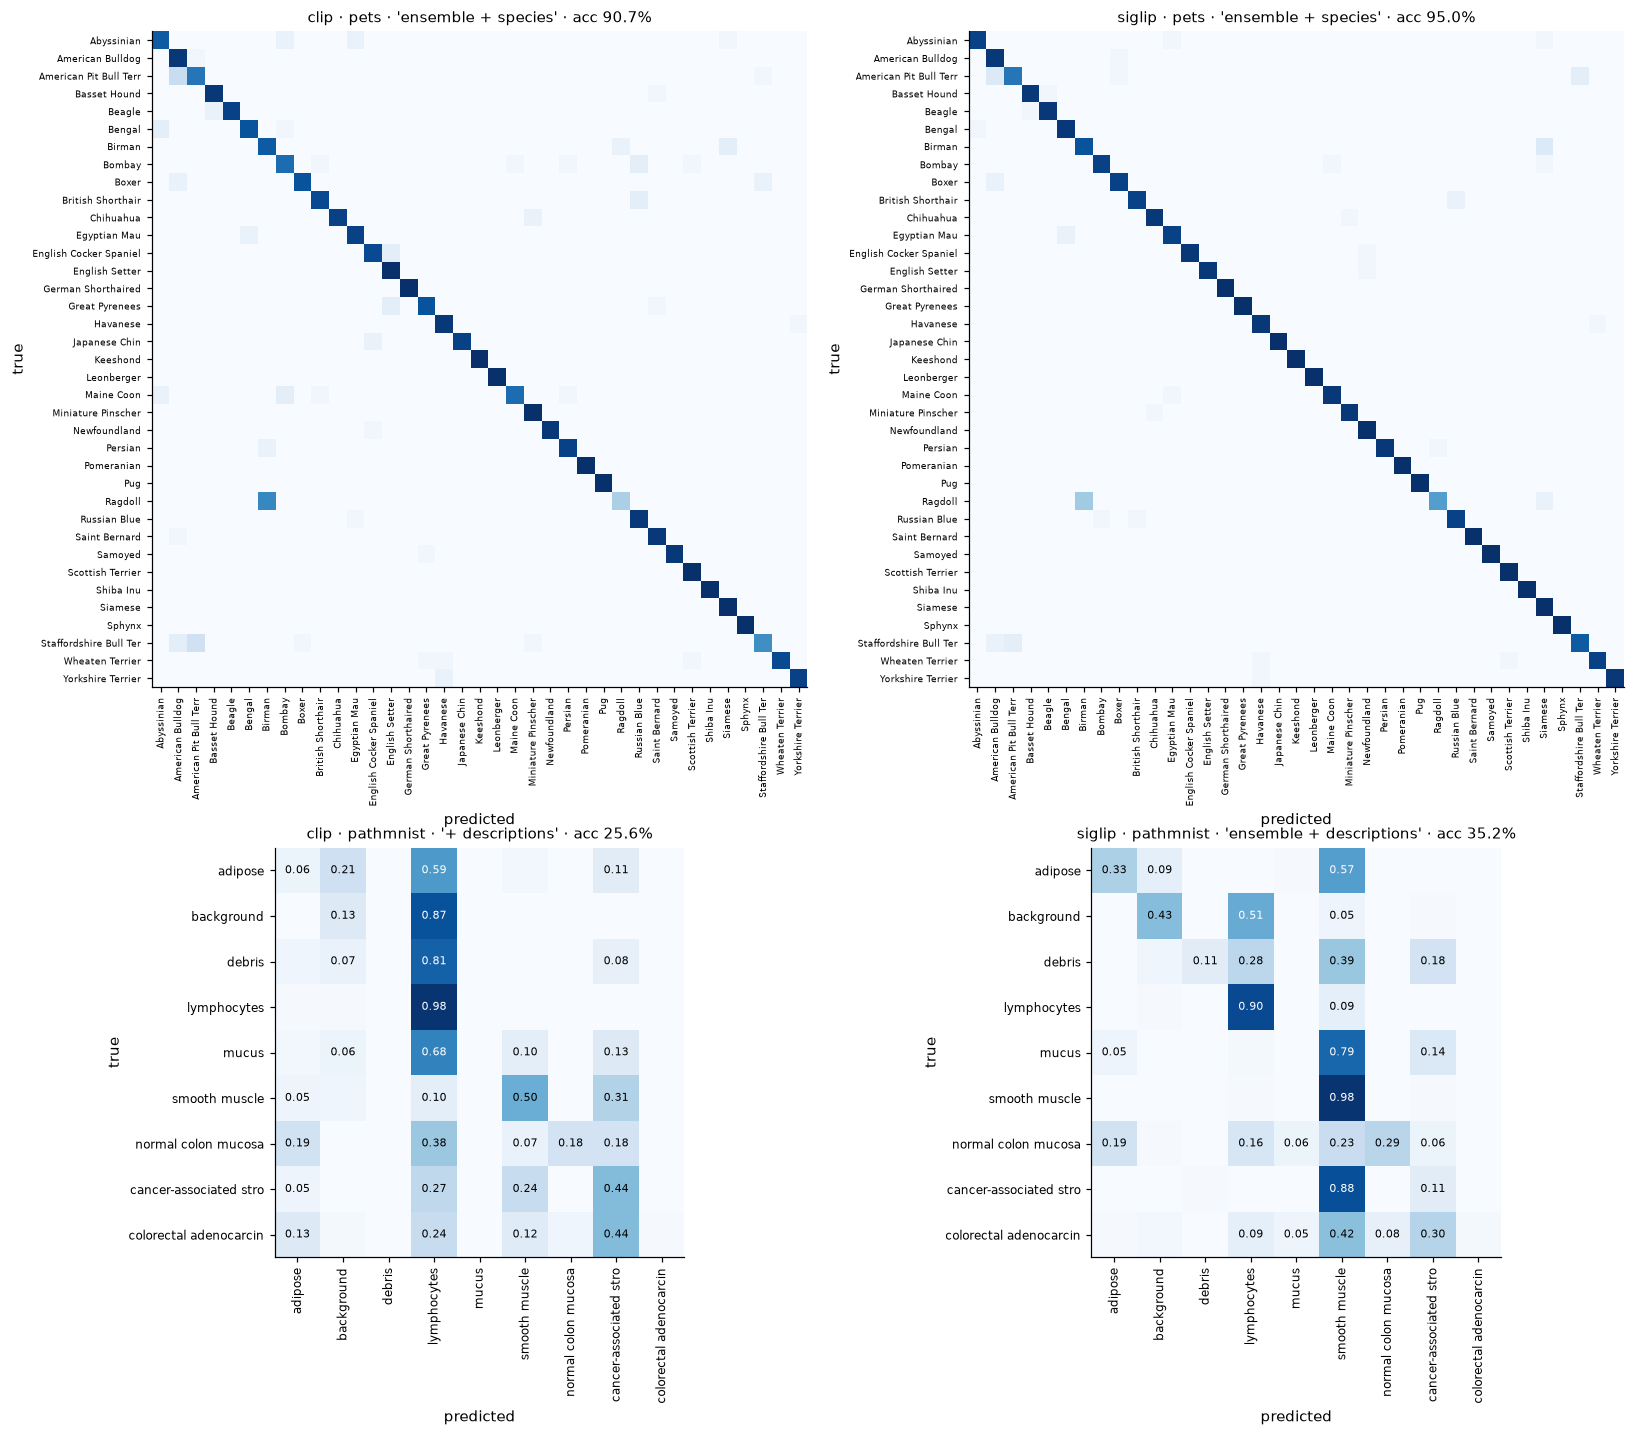

In [7]:
best = zs.loc[zs.groupby(["dataset", "model"]).accuracy.idxmax()].set_index(["dataset", "model"])
display(best.style.format({"accuracy": "{:.1%}"}))

fig, axes = plt.subplots(2, 2, figsize=(15, 13), gridspec_kw={"height_ratios": [1.6, 1]})
for row, name in enumerate(DATASETS):
    for col, key in enumerate(models):
        E, y, classes = test[key, name]
        strat = best.loc[(name, key), "strategy"]
        pred = (E @ weights[key, name, strat].T).argmax(1)
        cm = confusion_matrix(y, pred, normalize="true")
        ax = axes[row, col]
        ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
        short = [c[:22] for c in classes]
        fs = 6 if len(classes) > 10 else 8
        ax.set_xticks(range(len(classes)), short, rotation=90, fontsize=fs)
        ax.set_yticks(range(len(classes)), short, fontsize=fs)
        if len(classes) <= 10:
            for (i, j), v in np.ndenumerate(cm):
                if v >= 0.05:
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if v > 0.5 else "black")
        ax.set_xlabel("predicted"); ax.set_ylabel("true")
        ax.set_title(f"{key} · {name} · '{strat}' · acc {(pred == y).mean():.1%}", fontsize=10)
fig.tight_layout()
fig.savefig(cu.FIG_DIR / "zero_shot_confusion.png", bbox_inches="tight")

Pets errors are almost all between **visually similar breeds**: Ragdoll → Birman / Siamese (colorpoint long-haired cats), American Pit Bull Terrier → American Bulldog / Staffordshire Bull Terrier. A non-expert person would make the same mistakes, and some are arguably label noise.

PathMNIST errors are different in kind: whole **columns** light up. Many tissue types collapse onto one "attractor" label whose text happens to sit closest to all histology images: *lymphocytes* for CLIP (it absorbs 87% of background and 81% of debris tiles), *smooth muscle* for SigLIP (88% of stroma, 79% of mucus). Mucus and adenocarcinoma are essentially never predicted correctly by either model. That is the signature of a text side that can't tell the classes apart, rather than an image side that can't.

### A few misclassified examples

Using downloaded and verified file: data/medmnist/pathmnist_64.npz


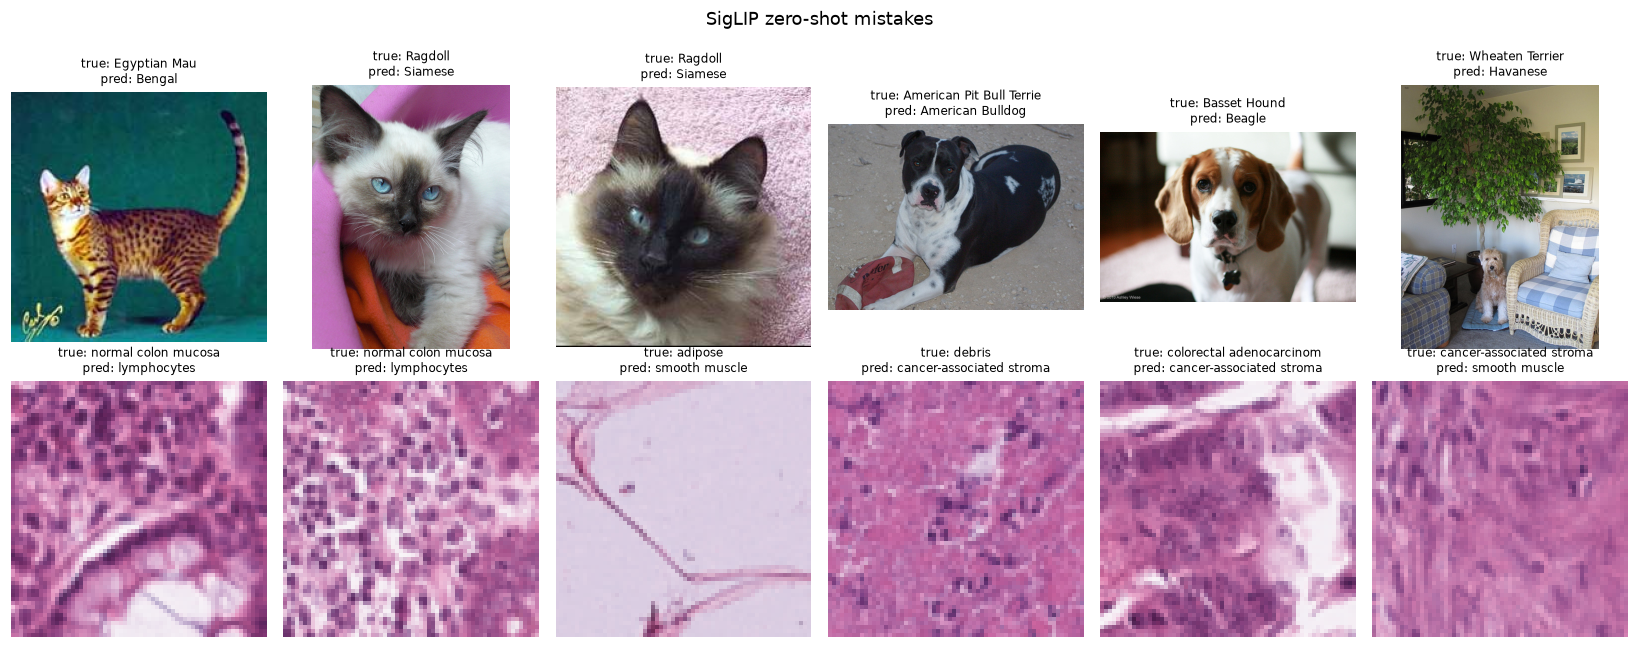

In [8]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 6, figsize=(15, 6))
for row, name in enumerate(DATASETS):
    key = "siglip"
    s = cu.load_imageset(name, "test")
    E, y, classes = test[key, name]
    pred = (E @ weights[key, name, best.loc[(name, key), "strategy"]].T).argmax(1)
    wrong = rng.choice(np.flatnonzero(pred != y), 6, replace=False)
    for ax, i in zip(axes[row], wrong):
        ax.imshow(s.image(int(i))); ax.axis("off")
        ax.set_title(f"true: {classes[y[i]][:24]}\npred: {classes[pred[i]][:24]}", fontsize=8)
fig.suptitle("SigLIP zero-shot mistakes")
fig.tight_layout()
fig.savefig(cu.FIG_DIR / "zero_shot_mistakes.png", bbox_inches="tight")

## 5. Save the best zero-shot classifiers for notebook 03

Notebook 03 compares these against linear probes, and also blends the two. Saving the text-derived weight matrix `W` (plus the model's logit scale) means notebook 03 doesn't need to load the models.

In [9]:
for (name, key), r in best.iterrows():
    m, _ = models[key]
    scale, bias = cu.logit_params(m)
    np.savez(cu.RESULTS_DIR / f"zeroshot_{name}_{key}.npz", W=weights[key, name, r.strategy],
             scale=scale, bias=bias, strategy=r.strategy)
zs.to_csv(cu.RESULTS_DIR / "zero_shot_prompts.csv", index=False)
print(sorted(f.name for f in cu.RESULTS_DIR.glob("zeroshot_*.npz")))

['zeroshot_pathmnist_clip.npz', 'zeroshot_pathmnist_siglip.npz', 'zeroshot_pets_clip.npz', 'zeroshot_pets_siglip.npz']


## 6. Bonus: zero-shot on your own photos

This is where zero-shot is most useful: a pile of unlabeled images and a list of labels you just made up.

1. Put some images (`.jpg`, `.png`, …) in `data/unlabeled/`.
2. Edit `MY_LABELS` below to whatever categories you care about.
3. Run the cell. Nothing gets trained.

(For a *labeled* evaluation of your own photos, put them in `data/my_photos/<class name>/` and set `DATASETS = ["my_photos"]` in notebooks 01–03.)

In [10]:
from PIL import Image

MY_LABELS = ["a dog", "a cat", "a beach", "a mountain landscape", "a city street", "food on a plate",
             "a group of people", "a screenshot or document", "a plant or flower", "a microscope image"]

folder = cu.DATA_DIR / "unlabeled"
files = sorted(f for f in folder.glob("*") if f.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"})[:12] if folder.exists() else []
if not files:
    print(f"No images found in {folder} - add some and re-run this cell.")
else:
    m, p = models["siglip"]
    W = cu.zeroshot_weights(m, p, [[f"a photo of {l}."] for l in MY_LABELS])
    imgs = [Image.open(f).convert("RGB") for f in files]
    S = cu.encode_images(m, p, imgs) @ W.T
    ncols = 4
    fig, axes = plt.subplots(int(np.ceil(len(imgs) / ncols)), ncols, figsize=(14, 3.6 * np.ceil(len(imgs) / ncols)), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, img, sims in zip(axes.ravel(), imgs, S):
        top = np.argsort(-sims)[:3]
        ax.imshow(img)
        ax.set_title("\n".join(f"{MY_LABELS[t]} ({sims[t]:.3f})" for t in top), fontsize=8)
    fig.tight_layout()

No images found in data/unlabeled - add some and re-run this cell.


## Takeaways

* A zero-shot classifier is a **linear classifier whose weights come from text**. You "train" it by writing sentences.
* Prompt wording is a real hyperparameter. Context ("a type of pet", "histopathology") and ensembling usually help; injected knowledge (species, visual descriptions) can help more. Choose prompts on validation data, not test data.
* Zero-shot is only as good as the model's **text–image alignment for your domain**. Everyday photos: excellent. Specialized imagery like histology: often near chance, even though the image features themselves are informative (UMAP in notebook 01).

Next: [03_linear_probe.ipynb](03_linear_probe.ipynb). How many labeled images does it take to beat these zero-shot classifiers?